# Feasibility demo: morpho-phonology in a speech model's word space, and a past-tense pilot

**CAS 784, Group 3** (Bart, Tanya, Nigel), Milestone 3.

We reproduce the main analogy results of Gauthier, Breiss, Leonard & Chang (2025), *Emergent morpho-phonological representations in self-supervised speech models* (EMNLP 2025).
Then we pilot our own question on the same data: **does the model represent the English past tense with one shared direction across [t] / [d] / [ɪd], and how do irregular verbs relate to it?**

- **Reading the numbers.** Every number is the **rank** of the correct word among 334,008 spoken word tokens: 0 means the model's guess is exactly right, and lower is better.
- **Statistics.** We report the mean rank (the paper's metric), and top-1 accuracy (the share of trials with rank 0) as a robust companion. 95% confidence intervals come from resampling *target words*, not trials. Medians are in the tables.
- **Data.** The notebook reads only the small files in `outputs/feasibility/data/`, written by `scripts/feasibility/02_export_compact_data.py`.

In [1]:
import sys, json
from pathlib import Path

# find the repo (or share-bundle) root from wherever the notebook is run
here = Path.cwd().resolve()
REPO = next(p for p in [here, *here.parents] if (p / "scripts/feasibility/common.py").exists())
sys.path[:0] = [str(REPO / "scripts/feasibility"), str(REPO / "scripts")]

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize
from IPython.display import display, Markdown

import common as C
from summarize_analogy_results import fig3, fig4, unambiguous_results

C.set_style()
pd.set_option("display.precision", 3, "display.width", 160)

results = pd.concat([pd.read_parquet(C.DATA / f"results_{m.lower()}.parquet") for m in C.MODELS], ignore_index=True)
vbd = pd.read_parquet(C.DATA / "vbd_trials.parquet")
pairs = pd.read_parquet(C.DATA / "pairs_vbd.parquet")
trainer_log = pd.read_csv(C.DATA / "trainer_log.csv")
spec_summary = json.loads((C.DATA / "spec_summary.json").read_text())
print(f"data root: {C.ROOT}")
print(f"{len(results):,} analogy trials ({results.experiment.nunique()} experiments x {results.model.nunique()} models); "
      f"{len(vbd):,} past-tense trials; {len(pairs)} past-tense pairs")

data root: I:\Python\CAS 784\Morph-2-Vec
216,120 analogy trials (120 experiments x 2 models); 6,000 past-tense trials; 949 past-tense pairs


## 1. Setup and data

- **Model.** We use the raw hidden states of layer 8 of `facebook/wav2vec2-base`. The paper calls this model **Wav2Vec**.
- **Probe.** We also use a **word probe**: a *linear* map from the 768-d states down to 32 dimensions. It is trained only to tell spoken words apart (contrastive hinge loss, the paper's Table 9 hyperparameters). The paper calls it **Word**.
- **Data.** LibriSpeech `train-clean-100`: 100.5 h of read English, 28,538 utterances, 18.1M frames of 20 ms. Each spoken word token is represented by the mean of its frames.
- **Analogies.** A trial predicts *d* from *a : b :: c : ?* as b − a + c. We then ask where the true *d* lands among all 334,008 tokens.
- **What to look at in the table:** our analogy universe has exactly the paper's number of tokens.

In [2]:
n_nns, n_vbz = spec_summary["unambiguous_pairs"]["NNS"], spec_summary["unambiguous_pairs"]["VBZ"]
evals = trainer_log.dropna(subset=["eval_loss"])
best = evals.loc[evals.eval_loss.idxmin()]
sanity = pd.DataFrame([
    ("Audio (train-clean-100)", f"{C.AUDIO_HOURS} h, {C.N_UTTERANCES:,} utterances", "100 h"),
    ("Frames (20 ms)", f"{spec_summary['total_num_frames']:,}", "—"),
    ("Word tokens in the analogy universe (≤ 100 per type)", f"{spec_summary['n_tokens']:,} ({spec_summary['n_labels']:,} types)", f"{C.PAPER_N_TOKENS:,}"),
    ("Unambiguous nouns / verbs (regular inflection)", f"{n_nns} / {n_vbz} ({spec_summary['unambiguous_VBZ_after_exclusions']} verbs after the authors' exclusions)",
     f"{C.PAPER_N_UNAMBIGUOUS[0]} / {C.PAPER_N_UNAMBIGUOUS[1]} (after manual exclusion)"),
    ("Probe", "linear 768 → 32, 24,576 weights + 32 biases", "same"),
    ("Probe hyperparameters", "margin 0.3759, lr 1.08e-3, weight decay 6.07e-3", "Table 9: same"),
    ("Probe eval mAP at the best checkpoint", f"{best.eval_mAP:.3f} (step {int(best.step)})", "not reported"),
], columns=["quantity", "ours", "paper"])
C.save_table(sanity, "table1_sanity")
sanity.style.hide(axis="index")

quantity,ours,paper
Audio (train-clean-100),"100.49 h, 28,538 utterances",100 h
Frames (20 ms),"18,087,600",—
Word tokens in the analogy universe (≤ 100 per type),"334,008 (32,046 types)","334,008"
Unambiguous nouns / verbs (regular inflection),776 / 59 (53 verbs after the authors' exclusions),753 / 52 (after manual exclusion)
Probe,"linear 768 → 32, 24,576 weights + 32 biases",same
Probe hyperparameters,"margin 0.3759, lr 1.08e-3, weight decay 6.07e-3",Table 9: same
Probe eval mAP at the best checkpoint,0.832 (step 3200),not reported


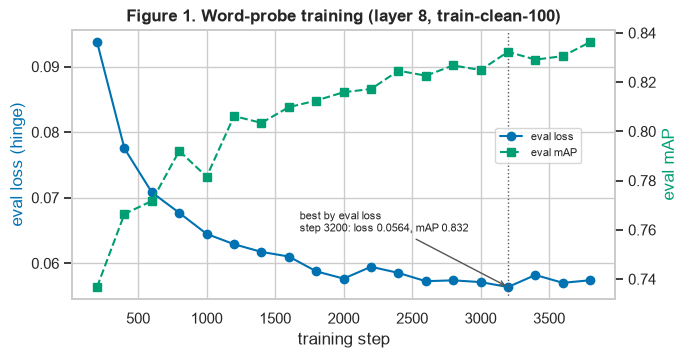

In [3]:
fig, ax1 = plt.subplots(figsize=(7, 3.5))
ax2 = ax1.twinx()
ax1.plot(evals.step, evals.eval_loss, "o-", color=C.MODEL_COLORS["Word"], label="eval loss")
ax2.plot(evals.step, evals.eval_mAP, "s--", color="#009E73", label="eval mAP")
ax1.axvline(best.step, color="#555555", lw=1, ls=":")
ax1.annotate(f"best by eval loss\nstep {int(best.step)}: loss {best.eval_loss:.4f}, mAP {best.eval_mAP:.3f}",
             (best.step, best.eval_loss), xytext=(-150, 40), textcoords="offset points", fontsize=8,
             arrowprops={"arrowstyle": "->", "color": "#555555"})
ax1.set_xlabel("training step")
ax1.set_ylabel("eval loss (hinge)", color=C.MODEL_COLORS["Word"])
ax2.set_ylabel("eval mAP", color="#009E73")
ax2.grid(False)
ax1.set_title("Figure 1. Word-probe training (layer 8, train-clean-100)")
fig.legend(loc="center right", bbox_to_anchor=(0.86, 0.55), fontsize=8)
C.save_fig(fig, "fig01_probe_training")
plt.show()

Training stopped early after three evaluations without an improvement in eval loss, and the best checkpoint (step 3,200) was reloaded. It took about 25 minutes on an RTX 3080 Ti.

*Lesson from the run:* our first attempt reported `eval_loss = NaN` from the very first evaluation. The eval set had 7,753 examples = 969 × 8 + **1**, and the hinge loss was NaN for the final one-example batch, which has no negative pairs. Early stopping therefore never saw an improvement. We fixed the loss to return 0 for batches without pairs.

## 2. Reproduction of the paper's Figs. 3 and 4

The paper's analogies use 753 nouns and 52 verbs whose inflected forms are unambiguously a plural noun (NNS) or a 3rd-person verb (VBZ).
- **Fig. 3** asks whether "add the inflection" transfers *across* morphological categories (noun → verb).
- **Fig. 4** asks whether it transfers across the pronunciations [s] / [z] / [ɪz].

As in the paper, we drop 6 verbs whose forms sound like another word (*knows* ~ *nose*, *meets* ~ *meats*, …).
First, a check that our numbers match the summary script (`scripts/summarize_analogy_results.py`), which applies no exclusions:

In [4]:
# Cross-check: with no exclusions, the same functions on the same trials give what the summary script printed
for model in C.MODELS:
    df = results[results.model == model]
    ours3 = fig3(df)
    for (m, src, tgt), v in C.SCRIPT_FIG3.items():
        if m == model:
            assert ours3.loc[src, tgt] == v, (model, src, tgt, ours3.loc[src, tgt], v)
    ours4 = fig4(df).loc[C.SCRIPT_FIG4[model].index, C.SCRIPT_FIG4[model].columns]
    ref = C.SCRIPT_FIG4[model]
    # the probe's cells are recorded to 2 decimals (exact); the raw-wav2vec cells to ~2 significant figures
    tol = 0.006 if model == "Word" else np.maximum(0.006, 0.05 * ref)
    assert (np.abs(ours4 - ref) <= tol).all().all(), (ours4 - ref)
print("OK: unexcluded Fig. 3 and Fig. 4 means equal summarize_analogy_results.py's output for both models")

OK: unexcluded Fig. 3 and Fig. 4 means equal summarize_analogy_results.py's output for both models


In [5]:
u = unambiguous_results(results)
u_excl = u[~u.excluded]
s3 = C.rank_summary(u_excl, ["model", "src_inflection", "tgt_inflection"])
unexcl = u.groupby(["model", "src_inflection", "tgt_inflection"]).gt_label_rank.mean().rename("mean_rank_no_exclusions")
s3 = s3.merge(unexcl.reset_index(), on=["model", "src_inflection", "tgt_inflection"])
s3["paper_mean_rank"] = [C.PAPER_FIG3[(m, a, b)] for m, a, b in zip(s3.model, s3.src_inflection, s3.tgt_inflection)]
C.save_table(s3, "table2_fig3_reproduction")
cols = ["model", "src_inflection", "tgt_inflection", "paper_mean_rank", "mean_rank_no_exclusions", "mean_rank", "mean_lo", "mean_hi",
        "median_rank", "top1", "n_trials", "n_items"]
s3[cols].style.hide(axis="index").format(precision=2)

model,src_inflection,tgt_inflection,paper_mean_rank,mean_rank_no_exclusions,mean_rank,mean_lo,mean_hi,median_rank,top1,n_trials,n_items
Wav2Vec,NNS,NNS,6.70,7.87,7.87,2.61,14.57,0.00,0.83,9000,748
Wav2Vec,NNS,VBZ,68.00,51.24,58.07,9.84,122.20,2.00,0.34,6689,52
Wav2Vec,VBZ,NNS,29.00,21.72,24.94,15.10,35.87,0.00,0.78,6702,748
Wav2Vec,VBZ,VBZ,37.00,36.29,38.09,15.41,66.70,0.00,0.77,2184,52
Word,NNS,NNS,1.00,0.88,0.88,0.65,1.14,0.00,0.86,9000,748
Word,NNS,VBZ,10.00,5.35,5.44,1.01,12.66,0.00,0.75,6689,52
Word,VBZ,NNS,2.70,3.24,3.69,2.95,4.45,0.00,0.79,6702,748
Word,VBZ,VBZ,7.90,5.87,6.26,1.23,15.88,0.00,0.84,2184,52


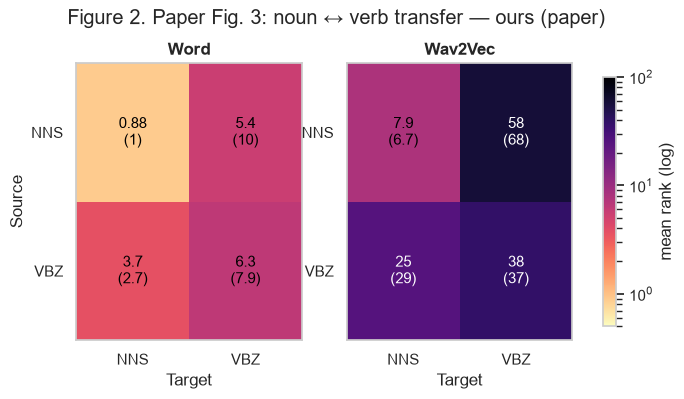

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(8, 3.6))
norm = LogNorm(vmin=0.5, vmax=100)
for ax, model in zip(axs, C.MODELS):
    s = s3[s3.model == model].pivot(index="src_inflection", columns="tgt_inflection", values="mean_rank")
    p = s3[s3.model == model].pivot(index="src_inflection", columns="tgt_inflection", values="paper_mean_rank")
    annot = s.map(C.fmt_rank) + "\n(" + p.map(lambda v: f"{v:g}") + ")"
    im = C.heatmap(ax, s, annot, norm, title=model, fontsize=11, ylabel="Source" if model == C.MODELS[0] else "")
fig.colorbar(im, ax=axs, label="mean rank (log)", shrink=0.9)
fig.suptitle("Figure 2. Paper Fig. 3: noun ↔ verb transfer — ours (paper)", x=0.45, y=1.03)
C.save_fig(fig, "fig02_fig3_morphology")
plt.show()

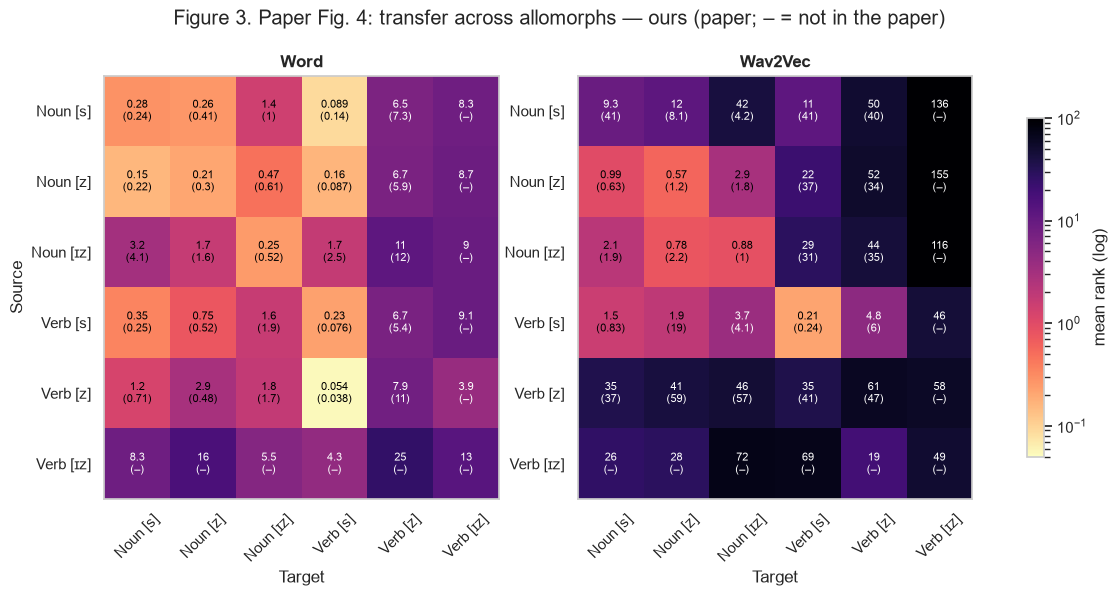

In [7]:
grid = u_excl.assign(src=lambda d: d.src_inflection.map({"NNS": "Noun", "VBZ": "Verb"}) + " [" + d.src_allomorph.map(C.ALLOMORPH_IPA) + "]",
                     tgt=lambda d: d.tgt_inflection.map({"NNS": "Noun", "VBZ": "Verb"}) + " [" + d.tgt_allomorph.map(C.ALLOMORPH_IPA) + "]")
s4 = C.rank_summary(grid, ["model", "src", "tgt"])
C.save_table(s4, "table3_fig4_allomorphs")
labels = ["Noun [s]", "Noun [z]", "Noun [ɪz]", "Verb [s]", "Verb [z]", "Verb [ɪz]"]
fig, axs = plt.subplots(1, 2, figsize=(14, 5.5))
norm = LogNorm(vmin=0.05, vmax=100)
for ax, model in zip(axs, C.MODELS):
    s = s4[s4.model == model].pivot(index="src", columns="tgt", values="mean_rank").reindex(index=labels, columns=labels)
    paper = C.PAPER_FIG4[model].reindex(index=labels, columns=labels)
    annot = s.map(C.fmt_rank) + "\n(" + paper.map(lambda v: f"{v:g}" if np.isfinite(v) else "–") + ")"
    im = C.heatmap(ax, s, annot, norm, title=model, fontsize=8, ylabel="Source" if model == C.MODELS[0] else "")
    ax.tick_params(axis="x", rotation=45)
fig.colorbar(im, ax=axs, label="mean rank (log)", shrink=0.8)
fig.suptitle("Figure 3. Paper Fig. 4: transfer across allomorphs — ours (paper; – = not in the paper)", x=0.45, y=1.0)
C.save_fig(fig, "fig03_fig4_allomorphs")
plt.show()

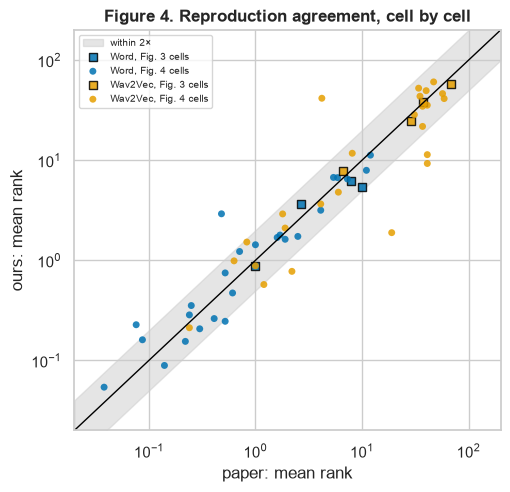

Cells within 2× of the paper: **Wav2Vec** 23/29; **Word** 26/29. Median ratio ours/paper: Wav2Vec 0.89; Word 0.94.

In [8]:
pts = []
for _, r in s3.iterrows():
    pts.append({"model": r.model, "figure": "Fig. 3", "cell": f"{r.src_inflection}→{r.tgt_inflection}", "paper": r.paper_mean_rank, "ours": r.mean_rank})
for _, r in s4.iterrows():
    if r.src in C.PAPER_FIG4[r.model].index and r.tgt in C.PAPER_FIG4[r.model].columns:
        pts.append({"model": r.model, "figure": "Fig. 4", "cell": f"{r.src}→{r.tgt}", "paper": C.PAPER_FIG4[r.model].loc[r.src, r.tgt], "ours": r.mean_rank})
pts = pd.DataFrame(pts)
pts["ratio"] = pts.ours / pts.paper
C.save_table(pts, "table4_reproduction_agreement")

fig, ax = plt.subplots(figsize=(5.5, 5.2))
lim = (0.02, 200)
xs = np.geomspace(*lim, 50)
ax.fill_between(xs, xs / 2, xs * 2, color="#cccccc", alpha=0.5, label="within 2×")
ax.plot(xs, xs, color="black", lw=1)
for model in C.MODELS:
    for figname, marker in [("Fig. 3", "s"), ("Fig. 4", "o")]:
        d = pts[(pts.model == model) & (pts.figure == figname)]
        ax.scatter(d.paper, d.ours, marker=marker, s=40 if marker == "s" else 25, color=C.MODEL_COLORS[model],
                   edgecolor="black" if marker == "s" else "none", label=f"{model}, {figname} cells", alpha=0.85)
ax.set(xscale="log", yscale="log", xlim=lim, ylim=lim, xlabel="paper: mean rank", ylabel="ours: mean rank")
within = pts.assign(w=lambda d: d.ratio.between(0.5, 2)).groupby("model").w.agg(["sum", "size"])
ax.set_title("Figure 4. Reproduction agreement, cell by cell")
ax.legend(fontsize=7, loc="upper left")
C.save_fig(fig, "fig04_reproduction_agreement")
plt.show()
display(Markdown("Cells within 2× of the paper: " + "; ".join(f"**{m}** {r['sum']}/{r['size']}" for m, r in within.iterrows())
                 + f". Median ratio ours/paper: " + "; ".join(f"{m} {v:.2f}" for m, v in pts.groupby('model').ratio.median().items()) + "."))

In [9]:
# medians next to means: the paper's median-rank figure (its Fig. 13) is all 0-3
med = s4.pivot_table(index="src", columns=["model", "tgt"], values="median_rank").reindex(labels)
C.save_table(med.reset_index(), "table5_fig4_medians")
med.loc[:, C.MODELS].round(1)

model         Word                                                 Wav2Vec                                               
tgt       Noun [s] Noun [z] Noun [ɪz] Verb [s] Verb [z] Verb [ɪz] Noun [s] Noun [z] Noun [ɪz] Verb [s] Verb [z] Verb [ɪz]
src                                                                                                                      
Noun [s]       0.0      0.0       0.0      0.0      0.0       2.0      0.0      0.0       0.0      0.0      2.0       9.0
Noun [z]       0.0      0.0       0.0      0.0      0.0       1.0      0.0      0.0       0.0      0.0      2.0       8.0
Noun [ɪz]      0.0      0.0       0.0      0.0      0.0       0.0      0.0      0.0       0.0      2.0      4.0       3.0
Verb [s]       0.0      0.0       0.0      0.0      0.0       2.0      0.0      0.0       0.0      0.0      0.0       1.0
Verb [z]       0.0      0.0       0.0      0.0      0.0       1.0      0.0      0.0       0.0      0.0      0.0       1.0
Verb [ɪz]      0.0      0.0       0.0      1.0      1.0       1.5      0.0      0.0       0.0      0.0      0.0       4.0

**What this shows.**
- **The reproduction holds.** All 8 Fig. 3 cells and 41 of 50 Fig. 4 cells are within 2× of the paper (probe 22/25, wav2vec 19/25). The median ratio of ours to the paper's is 0.94 for the probe and 0.89 for wav2vec.
- **The qualitative pattern matches.** The word probe transfers almost as well across noun ↔ verb, and across [s]/[z]/[ɪz], as within. It shows the paper's same weak spots: the *Verb [z]* target column and the *Noun [ɪz]* source row. Raw wav2vec is much more sensitive to both, e.g. NNS → VBZ is 58 vs. 5.4 for the probe.
- **Wav2vec's cells disagree with the paper more** (e.g. Noun [s] → Noun [s]: 9.3 vs. 41), because its means are driven by a few failed trials. Medians are 0 in most cells for both models, and top-1 accuracy is 0.77–0.87 in every Fig. 3 cell except wav2vec NNS → VBZ (0.34).

## 3. Baselines

How much better than "anything" are these analogies? The **random-pair control** takes the difference vector from a *random* pair of words (instead of a noun or verb inflection) and applies it to the same target bases.
- Left panel: mean rank (log scale, 95% CI).
- Right panel: top-1 accuracy.
- The small numbers under each bar are *n trials / n target words*.

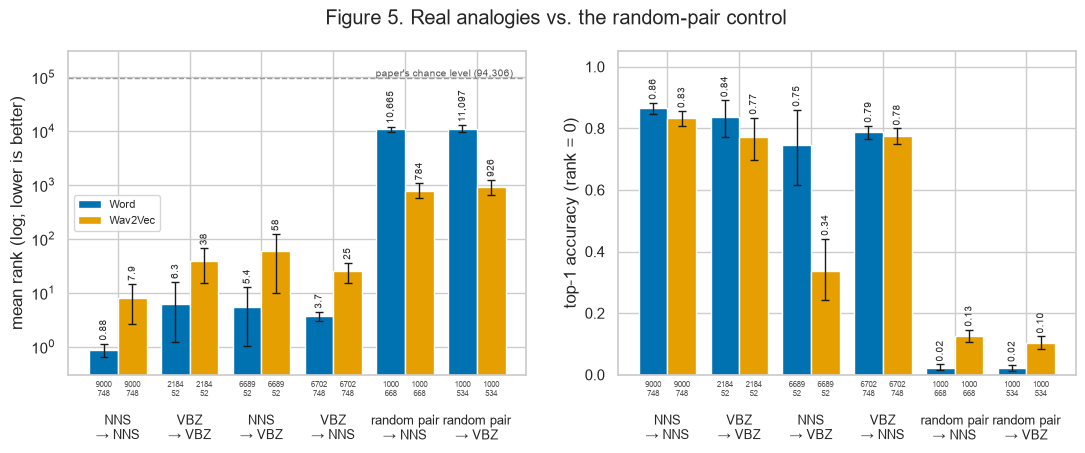

model,condition,mean_rank,mean_lo,mean_hi,median_rank,top1,n_trials,n_items
Wav2Vec,NNS → NNS,7.87,2.61,14.57,0.00,0.83,9000,748
Wav2Vec,NNS → VBZ,58.07,9.84,122.20,2.00,0.34,6689,52
Wav2Vec,VBZ → NNS,24.94,15.10,35.87,0.00,0.78,6702,748
Wav2Vec,VBZ → VBZ,38.09,15.41,66.70,0.00,0.77,2184,52
Wav2Vec,random pair → NNS,783.96,572.27,1069.26,28.00,0.13,1000,668
Wav2Vec,random pair → VBZ,926.00,653.63,1237.94,35.00,0.10,1000,534
Word,NNS → NNS,0.88,0.65,1.14,0.00,0.86,9000,748
Word,NNS → VBZ,5.44,1.01,12.66,0.00,0.75,6689,52
Word,VBZ → NNS,3.69,2.95,4.45,0.00,0.79,6702,748
Word,VBZ → VBZ,6.26,1.23,15.88,0.00,0.84,2184,52


In [10]:
conds = {
    "NNS\n→ NNS": u_excl[(u_excl.src_inflection == "NNS") & (u_excl.tgt_inflection == "NNS")],
    "VBZ\n→ VBZ": u_excl[(u_excl.src_inflection == "VBZ") & (u_excl.tgt_inflection == "VBZ")],
    "NNS\n→ VBZ": u_excl[(u_excl.src_inflection == "NNS") & (u_excl.tgt_inflection == "VBZ")],
    "VBZ\n→ NNS": u_excl[(u_excl.src_inflection == "VBZ") & (u_excl.tgt_inflection == "NNS")],
    "random pair\n→ NNS": results[results.experiment == "random_to_NNS"],
    "random pair\n→ VBZ": results[results.experiment == "random_to_VBZ"],
}
base = pd.concat([d.assign(condition=k) for k, d in conds.items()], ignore_index=True)
s5 = C.rank_summary(base, ["model", "condition"])
C.save_table(s5.assign(condition=s5.condition.str.replace("\n", " ")), "table6_baselines")
order = list(conds)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
C.ci_bars(axs[0], s5, "condition", order, log=True, ylabel="mean rank (log; lower is better)")
axs[0].axhline(C.PAPER_CHANCE_RANK, color=C.CONTROL_COLOR, ls="--", lw=1)
axs[0].text(len(order) - 0.5, C.PAPER_CHANCE_RANK, "paper's chance level (94,306)", ha="right", va="bottom", fontsize=7, color="#555555")
axs[0].set_ylim(0.3, 3e5)
C.ci_bars(axs[1], s5, "condition", order, est="top1", lo="top1_lo", hi="top1_hi", ylabel="top-1 accuracy (rank = 0)", fmt="{:.2f}")
axs[1].set_ylim(0, 1.05)
for ax in axs:
    ax.tick_params(axis="x", labelsize=9)
axs[0].legend(fontsize=8)
fig.suptitle("Figure 5. Real analogies vs. the random-pair control")
C.save_fig(fig, "fig05_baselines")
plt.show()
s5.assign(condition=s5.condition.str.replace("\n", " "))[["model", "condition", "mean_rank", "mean_lo", "mean_hi", "median_rank", "top1", "n_trials", "n_items"]].style.hide(axis="index").format(precision=2)

- **Real analogies are far better than the control.** Every real analogy is orders of magnitude better than the random-pair control: about 10,700–11,100 for the probe and about 780–930 for wav2vec. Top-1 accuracy drops from 0.75–0.86 to 0.02 (probe) and 0.10–0.13 (wav2vec).
- **This control is not the paper's chance level of 94,306.** The paper (§3.4) defines its random baseline the same way, by sampling a random counterfactual pair, so how it got 94,306 is an open question. We call ours the "random-pair control" and do not claim the two match.
- **Why the control is so much lower for wav2vec.** In raw wav2vec, *b − a + c* stays close to *c*, and an inflected form sounds like its base. Even a random difference vector therefore lands near the target.

## 4. Past-tense pilot: VBD analogies

This part is new. The analogy runs already contain past-tense trials (*walk : walked :: play : ?*), which the paper never summarized. We port the authors' own unpublished VBD analysis (their summary notebook, cells 69–84), without the word-frequency filter.

- **Regular verbs.** The past form is the base plus *-ed/-d/-t* (837 pairs). Source and target are both regular.
- **Irregular verbs** (112 pairs). Source and target are both irregular. There is no regular ↔ irregular transfer in the existing runs; that needs a new run (a next step).
- **Pronunciation.** The aligner writes the *-ed* syllable as either `IH D` or `AH D`, in a 65 : 35 ratio (`checks/id_label_check.md`). We count both as **[ɪd]**; the authors' code silently dropped the `AH D` verbs.
- **Authors' exclusions.** We also apply the authors' exclusions: stress-shift verbs (*record, permit, …*), *do, hide, make*, *dream, leap*.

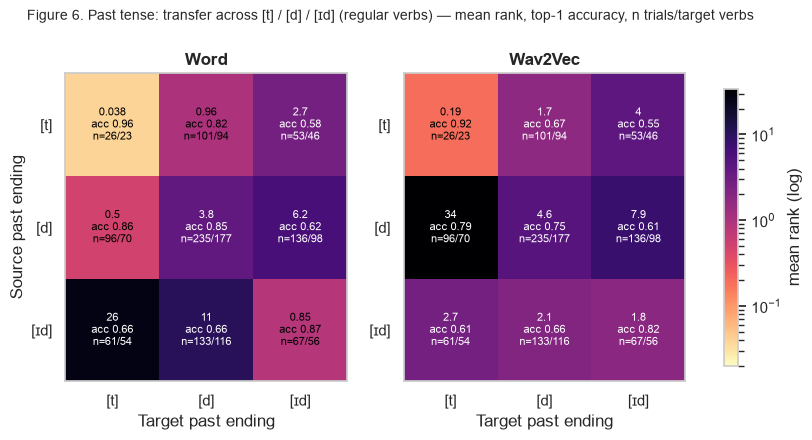

In [11]:
reg = vbd[(vbd.experiment == "regular") & (vbd.class_from == "regular") & ~vbd.authors_excluded].copy()
top3 = reg.allomorph_from_canon.value_counts().head(3).index.tolist()
assert set(top3) == {"T", "D", "IH D"}, top3
reg3 = reg[reg.allomorph_from_canon.isin(top3) & reg.allomorph_to_canon.isin(top3)].copy()
lab = {"T": "[t]", "D": "[d]", "IH D": "[ɪd]"}
reg3["src"], reg3["tgt"] = reg3.allomorph_from_canon.map(lab), reg3.allomorph_to_canon.map(lab)
s6 = C.rank_summary(reg3, ["model", "src", "tgt"])
C.save_table(s6, "table7_vbd_allomorph_grid")

order6 = ["[t]", "[d]", "[ɪd]"]
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
norm = LogNorm(vmin=0.02, vmax=max(30, s6.mean_rank.max()))
for ax, model in zip(axs, C.MODELS):
    s = s6[s6.model == model].set_index(["src", "tgt"])
    v = s.mean_rank.unstack().reindex(index=order6, columns=order6)
    annot = pd.DataFrame([[f"{C.fmt_rank(s.loc[(a, b), 'mean_rank'])}\nacc {s.loc[(a, b), 'top1']:.2f}\nn={s.loc[(a, b), 'n_trials']}/{s.loc[(a, b), 'n_items']}"
                           for b in order6] for a in order6], index=order6, columns=order6)
    im = C.heatmap(ax, v, annot, norm, title=model, fontsize=8, xlabel="Target past ending",
                   ylabel="Source past ending" if model == C.MODELS[0] else "")
fig.colorbar(im, ax=axs, label="mean rank (log)", shrink=0.9)
fig.suptitle("Figure 6. Past tense: transfer across [t] / [d] / [ɪd] (regular verbs) — mean rank, top-1 accuracy, n trials/target verbs",
             x=0.45, y=1.04, fontsize=10)
C.save_fig(fig, "fig06_vbd_allomorph_grid")
plt.show()

In [12]:
# how much the IH D / AH D mapping matters (the authors' raw labels drop the AH D verbs)
raw = reg[reg.allomorph_from.isin(["T", "D", "IH D"]) & reg.allomorph_to.isin(["T", "D", "IH D"])]
cmp = pd.concat({
    "authors' labels (IH D only)": raw.groupby(["model", "allomorph_from", "allomorph_to"]).gt_label_rank.agg(["size", "mean"]),
    "IH D + AH D = ɪd": reg3.groupby(["model", "allomorph_from_canon", "allomorph_to_canon"]).gt_label_rank.agg(["size", "mean"])
        .rename_axis(["model", "allomorph_from", "allomorph_to"]),
}, axis=1)
cmp.columns = [f"{a}: {'n' if b == 'size' else 'mean rank'}" for a, b in cmp.columns]
C.save_table(cmp.reset_index(), "table8_vbd_id_mapping")
cmp.round(2)

authors' labels (IH D only): n  authors' labels (IH D only): mean rank  IH D + AH D = ɪd: n  IH D + AH D = ɪd: mean rank
model   allomorph_from allomorph_to                                                                                                                          
Wav2Vec D              D                                        235                                    4.63                  235                         4.63
                       IH D                                      94                                   10.48                  136                         7.93
                       T                                         96                                   34.18                   96                        34.18
        IH D           D                                         93                                    2.05                  133                         2.08
                       IH D                                      32                                    0.91                   67                         1.78
                       T                                         37                                    1.78                   61                         2.69
        T              D                                        101                                    1.66                  101                         1.66
                       IH D                                      32                                    4.91                   53                         4.04
                       T                                         26                                    0.19                   26                         0.19
Word    D              D                                        235                                    3.83                  235                         3.83
                       IH D                                      94                                    7.16                  136                         6.15
                       T                                         96                                    0.50                   96                         0.50
        IH D           D                                         93                                   12.75                  133                        10.65
                       IH D                                      32                                    0.38                   67                         0.85
                       T                                         37                                    2.86                   61                        25.57
        T              D                                        101                                    0.96                  101                         0.96
                       IH D                                      32                                    3.19                   53                         2.68
                       T                                         26                                    0.04                   26                         0.04

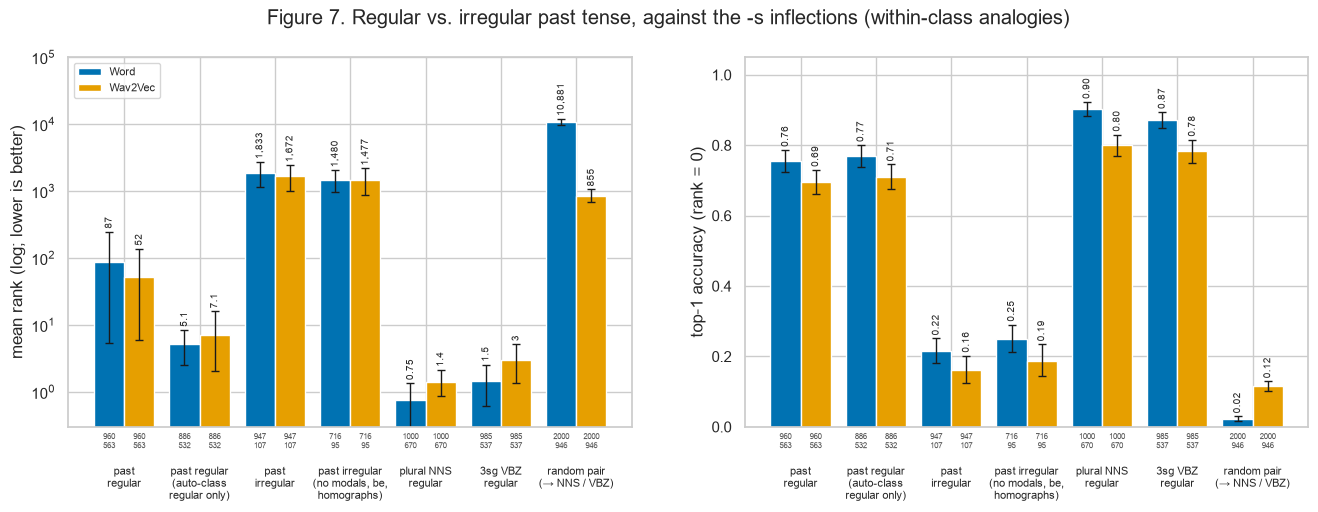

model,condition,mean_rank,mean_lo,mean_hi,median_rank,top1,top1_lo,top1_hi,n_trials,n_items
Wav2Vec,3sg VBZ regular,3.04,1.37,5.17,0.00,0.78,0.75,0.82,985,537
Wav2Vec,past irregular,1671.53,994.79,2436.44,27.00,0.16,0.12,0.20,947,107
Wav2Vec,past regular,52.33,6.04,137.69,0.00,0.69,0.66,0.73,960,563
Wav2Vec,"past irregular (no modals, be, homographs)",1477.23,868.90,2175.06,19.00,0.19,0.15,0.23,716,95
Wav2Vec,past regular (auto-class regular only),7.08,2.01,15.97,0.00,0.71,0.68,0.75,886,532
Wav2Vec,plural NNS regular,1.42,0.86,2.14,0.00,0.80,0.77,0.83,1000,670
Wav2Vec,random pair (→ NNS / VBZ),854.98,675.51,1056.97,31.00,0.12,0.10,0.13,2000,946
Word,3sg VBZ regular,1.46,0.62,2.55,0.00,0.87,0.85,0.89,985,537
Word,past irregular,1832.97,1133.19,2711.73,42.00,0.22,0.18,0.25,947,107
Word,past regular,87.28,5.35,247.99,0.00,0.76,0.72,0.79,960,563


In [13]:
# Figure 7: regular vs. irregular past, against the -s inflections in the same `regular` experiment
flagged = set(C.SUPPLETIVE_PAIRS) | set(C.HOMOGRAPH_PASTS) \
    | set(map(tuple, pairs.loc[pairs.inflected.isin(C.MODAL_PASTS) | (pairs.n_pasts_for_base > 1), ["base", "inflected"]].to_numpy()))
vreg = vbd[(vbd.experiment == "regular") & ~vbd.authors_excluded]
irr = vreg[vreg.class_from == "irregular"]
is_flagged = [(b, i) in flagged or (b2, i2) in flagged
              for b, i, b2, i2 in zip(irr.base_from, irr.inflected_from, irr.base_to, irr.inflected_to)]
rres = results[(results.experiment == "regular") & ~results.excluded]
# automatic first-guess class of each pair (common.auto_class; the manual annotation will replace it)
pairs[["auto_class", "auto_reason"]] = pairs.apply(C.auto_class, axis=1, result_type="expand")
clean_regular = set(map(tuple, pairs.loc[pairs.auto_class.str.startswith("regular_"), ["base", "inflected"]].to_numpy()))
vr = vreg[vreg.class_from == "regular"]
is_clean = [(b, i) in clean_regular and (b2, i2) in clean_regular
            for b, i, b2, i2 in zip(vr.base_from, vr.inflected_from, vr.base_to, vr.inflected_to)]
conds7 = {
    "past\nregular": vr,
    "past regular\n(auto-class\nregular only)": vr[np.array(is_clean)],
    "past\nirregular": irr,
    "past irregular\n(no modals, be,\nhomographs)": irr[~np.array(is_flagged)],
    "plural NNS\nregular": rres[(rres.group0 == "NNS") & (rres.group1 == True)],
    "3sg VBZ\nregular": rres[(rres.group0 == "VBZ") & (rres.group1 == True)],
    "random pair\n(→ NNS / VBZ)": results[results.experiment.isin(["random_to_NNS", "random_to_VBZ"])],
}
d7 = pd.concat([d.assign(condition=k) for k, d in conds7.items()], ignore_index=True)
s7 = C.rank_summary(d7, ["model", "condition"])
C.save_table(s7.assign(condition=s7.condition.str.replace("\n", " ")), "table9_regular_vs_irregular")
order7 = list(conds7)
fig, axs = plt.subplots(1, 2, figsize=(16, 4.8))
C.ci_bars(axs[0], s7, "condition", order7, log=True, ylabel="mean rank (log; lower is better)")
axs[0].set_ylim(0.3, 1e5)
C.ci_bars(axs[1], s7, "condition", order7, est="top1", lo="top1_lo", hi="top1_hi", ylabel="top-1 accuracy (rank = 0)", fmt="{:.2f}")
axs[1].set_ylim(0, 1.05)
for ax in axs:
    ax.tick_params(axis="x", labelsize=8)
axs[0].legend(fontsize=8)
fig.suptitle("Figure 7. Regular vs. irregular past tense, against the -s inflections (within-class analogies)")
C.save_fig(fig, "fig07_regular_vs_irregular")
plt.show()
s7.assign(condition=s7.condition.str.replace("\n", " "))[["model", "condition", "mean_rank", "mean_lo", "mean_hi", "median_rank", "top1", "top1_lo", "top1_hi", "n_trials", "n_items"]] \
    .style.hide(axis="index").format(precision=2)

In [14]:
# Worst / best target verbs (authors' cells 79-81), regular verbs, by target ending; with homophones of the past form
hom = pairs.drop_duplicates("inflected").set_index("inflected").past_homophones
per_verb = reg3.groupby(["model", "tgt", "base_to", "inflected_to"]).gt_label_rank.agg(mean_rank="mean", trials="size").reset_index()
per_verb["past_sounds_like"] = per_verb.inflected_to.map(hom).fillna("")
worst = per_verb.sort_values("mean_rank", ascending=False).groupby(["model", "tgt"]).head(15)
best_ = per_verb.sort_values(["mean_rank", "trials"], ascending=[True, False]).groupby(["model", "tgt"]).head(15)
C.save_table(pd.concat({"worst": worst, "best": best_}).reset_index(level=0, names="which"), "table10_vbd_worst_best_targets")
share_hom = per_verb.assign(h=per_verb.past_sounds_like != "").groupby([per_verb.mean_rank > 100, "h"]).size()
display(Markdown("**Worst 15 target verbs per model** (all endings pooled; the full lists by ending are in `tables/table10_vbd_worst_best_targets.csv`):"))
worst_all = per_verb.sort_values("mean_rank", ascending=False).groupby("model").head(15)
display(worst_all.rename(columns={"tgt": "ending", "base_to": "base", "inflected_to": "past"}).style.hide(axis="index").format(precision=1))

**Worst 15 target verbs per model** (all endings pooled; the full lists by ending are in `tables/table10_vbd_worst_best_targets.csv`):

model,ending,base,past,mean_rank,trials,past_sounds_like
Wav2Vec,[t],tap,tapped,3129.0,1,
Word,[d],nose,nosed,829.0,1,
Wav2Vec,[d],row,rowed,728.0,1,rhode road rode
Word,[t],peep,peeped,327.3,3,
Wav2Vec,[ɪd],side,sided,292.0,2,
Word,[t],stalk,stalked,231.0,1,
Word,[ɪd],side,sided,186.0,2,
Word,[d],curl,curled,182.0,2,curl'd
Word,[d],row,rowed,173.0,1,rhode road rode
Wav2Vec,[ɪd],tend,tended,81.0,2,


**What the pilot shows** (cautiously; one probe seed, one layer):
- **Regular past-tense transfer across [t] / [d] / [ɪd] works** (Figure 6).
  - In the probe, every cell has top-1 accuracy ≥ 0.58 (26–235 trials per cell). Within-ending cells are best (0.85–0.96), and transfer *into* [ɪd] is weakest (0.58–0.62).
  - That is the same kind of mild allomorph sensitivity the paper reports for -s.
  - The probe is at or above raw wav2vec in top-1 accuracy in all 9 cells, but the confidence intervals overlap in most of them. In this pilot the probe's advantage is smaller than for -s.
- **Outliers drive the means, and a linguistic classification fixes them** (Figure 7).
  - The regular-past mean (87 for the probe) comes almost entirely from a handful of pairs that the pipeline calls "regular" but that change their stem: *bath → bathed* [bæθ → beɪðd], *deal → dealt*, *mean → meant*. The worst 1% of trials carry 95% of the total rank.
  - Keeping only pairs whose automatic class is regular [t]/[d]/[ɪd] brings the mean to **5.1** for the probe and **7.1** for wav2vec. That is close to the -s inflections (0.75–3.0).
- **Irregular → irregular analogies mostly fail.**
  - Top-1 accuracy is 0.22 for the probe and 0.16 for wav2vec, vs. 0.77 / 0.71 for clean regular pasts. Mean ranks are about 1,500–1,800, between the real inflections and the random-pair control.
  - Removing modals, *be* and homographs barely changes this.
  - This is expected under every account, because *sing : sang :: take : ?* mixes different sound changes. The informative tests are regular ↔ irregular transfer and transfer within a sound-change family; both are next.
- **The worst target verbs** include several whose past form sounds like another word (*rowed ~ road/rode*, *missed ~ mist*). Homophones are not excluded at ranking time, so their ranks are inflated.

## 6. What we learned, and how the project changes

*Draft; the team will edit this.*

**What reproduced.**
- Our analogy universe matches the paper exactly (334,008 tokens).
- Figs. 3 and 4 reproduce cell by cell: all 8 Fig. 3 cells and 41 of 50 Fig. 4 cells are within 2× of the paper.
- The qualitative pattern is the same: the word probe is nearly invariant to morphology and allomorph, and raw wav2vec is not.

**What didn't, or isn't settled.**
- *False friends (paper Fig. 5).* These reproduce in direction only: our ranks are 3–8× the paper's. The likely reason is the word-frequency (WorldLex) filter we could not apply.
- *Chance level.* The paper defines its random baseline exactly as our random-pair control, yet reports 94,306, which is far above our control. How that number was computed is an open question.

**Costs.** One layer of `train-clean-100` takes about 8–9 h end to end, about 3.5 h of which repeats for each extra layer. The hidden states take 52 GB per layer. Our machine (32 GB RAM, 12 GB GPU) needed about 20 fixes, mostly for memory and Windows (see `Project_Feasibility.md`).

**The past-tense pilot.**
- **Data.** 949 past-tense pairs with at least 6 tokens of both forms: 837 regular and 112 irregular. 98 irregulars remain after removing modals, *be*, homographs and verbs with two past forms.
- **Regular verbs.** The regular past transfers across [t] / [d] / [ɪd] (probe top-1 accuracy 0.58–0.96 per cell).
- **Irregular verbs.** Irregular → irregular mostly fails (top-1 ≈ 0.2).
- **Labelling matters.** The pipeline's "regular" label lets in stem-changing verbs (*bathed, dealt, meant*) that dominate the mean ranks. **A manual linguistic classification of the verbs is needed before any claim**, and it will define the verb groups for the main experiment.

**Decisions for the proposal.**
- The scope is the **past tense**. A newer speech model is at most a stretch goal.
- The verb set uses **manually annotated classes**: regular [t]/[d]/[ɪd], semi-regular (*kept*), devoicing (*sent*), ablaut (*sang*), suppletive (*went*), plus exclusions.
- **Measures:** the cosine between per-verb past-tense offset vectors, plus analogy rank. Ranks are reported as mean rank and top-1 accuracy with target-word bootstrap CIs (medians are almost always 0).
- **Main generalization test:** held-out verbs (leave one verb out). `test-clean` is only a check, because its item counts are small.
- **Out of scope, or a stated limitation:** participles (*sung*) and zero-change verbs (*put, hit*).
- **The missing experiment:** regular ↔ irregular transfer needs a new analogy run (about 3 h for both models).

**Known issues.**
- **The [ɪd] spelling.** `IH D` vs `AH D` drops many [ɪd] verbs from the ending-specific experiments, and leaves almost no [ɪd] forced-choice or false-friend items (fix: regenerate the stimuli).
- **Homophones are not excluded at ranking time.** A past form that sounds like another word (*made* ~ *maid*, *rode* ~ *road*) is penalized.
- **No noun/verb ambiguity control for the past tense.** The `base_ambig_NN_VB` flag is only computed for -s.
- **Mixed uses.** Spoken *walked* tokens mix past, participle and adjective uses; the POS tags are not stored.
- **The pipeline's `is_regular()`** lumps semi-regulars with strong irregulars, and calls *said, paid, meant* regular. The manual annotation replaces it.